# Chile: Anexo 1 de la RAN 21-13 sobre un balance en pesos y UF

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 a 05 de este tema
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este cuaderno puedes:

- explicar por qué el regulador chileno trata la UF como una moneda propia (la UR) con su propia curva, tamaños de choque, piso y cargo, y leer los dos tramos de un balance en pesos y UF;
- reconstruir con el motor las curvas de los dos tramos desde los rendimientos observados, y decir qué le falta a la curva en pesos;
- calcular el delta EVE de cada tramo bajo los seis choques, combinar los dos tramos con la regla de compensación de 50 por ciento, y obtener el delta EVE del Anexo 1;
- calcular el delta NII de cada tramo, sumar el cargo por reajustabilidad, y obtener el delta NII del Anexo 1;
- aplicar las tres pruebas que hacen priorizado a un banco, y leer la distancia de cada tasa posterior al choque a su piso;
- comparar cada recálculo con el valor versionado, nombrando la versión del motor que lo calculó.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import curves, eve_nii, shocks, slotting

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Los datos son el caso C15: **Banco Andino**, un banco **sintético** con un balance en pesos chilenos (CLP) y en UF (la unidad de cuenta reajustable chilena, CLF), a la fecha de valoración 2026-09-03. Sus agregados están calibrados a las cifras del sistema del informe de agosto de 2026 de la CMF (https://www.cmfchile.cl/portal/estadisticas/617/articles-113863_recurso_1.pdf, el regulador chileno, estadísticas públicas de la clase de licencia `mirror-allowed`); la proporción en UF, el perfil de reprecio de cada partida, la separación de depósitos y todo supuesto de comportamiento son sintéticos y están declarados en el documento. Las **curvas son reales**: los rendimientos del Banco Central de Chile (cuadro F022 de la BDE, `mirror-allowed`, atribución "Fuente: Banco Central de Chile, Base de Datos Estadísticos") y el valor de la UF de la fecha (serie F073.UFF.PRE.Z.D). El dinero está en millones de CLP; el tramo UF está en millones de CLF y se convierte con el valor de la UF solo donde se suman los dos tramos. El motor nunca convierte entre monedas.

El caso versiona seis variantes del mismo banco, cada una una tensión distinta sobre el balance: `short-uf` (corto neto en UF a 30 por ciento del Tier 1), `long-uf` (largo neto), `cpi-surprise` (largo neto, con una sorpresa de inflación de 2,5 puntos), `clp-steepener` (un balance en pesos más largo), `offset-on-off` (la regla de compensación comparada con y sin) y `floors-active` (70 por ciento de los préstamos comerciales en UF a tasa flotante, para poner en juego los pisos).

- **Archivos que se leen:** `data/derived/C15/short-uf.json`, `long-uf.json`, `cpi-surprise.json`, `clp-steepener.json`, `offset-on-off.json` y `floors-active.json` (`outputs.legs`, `curves`, `eve`, `nii`, `floors`, `offset_rule`, `indexation_charge`, `cpi_scenario`, `thresholds`; `tests`; `impact`) y `models-banco-andino-2026-09.json` (`fit.annex1_table`, `multipliers`, `nmd_caps`, `buckets`).

La celda siguiente carga los siete archivos e imprime la versión del motor que los calculó.

In [2]:
# Cargar las seis variantes y el documento de modelos (el cuaderno está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C15"
ids = ["short-uf", "long-uf", "cpi-surprise", "clp-steepener", "offset-on-off", "floors-active"]
variants = {v: json.loads((derived / f"{v}.json").read_text(encoding="utf-8")) for v in ids}
fit = json.loads((derived / "models-banco-andino-2026-09.json").read_text(encoding="utf-8"))["fit"]
out = variants["short-uf"]["outputs"]
MID = slotting.bucket_grid().midpoints
LANG = "es"  # los campos bilingües de los documentos se leen en este idioma
# Nombres en este idioma de los valores propios del documento (los identificadores del archivo quedan como están)
NAME = {"parallel-up": "paralelo al alza", "parallel-down": "paralelo a la baja", "steepener": "empinamiento",
        "flattener": "aplanamiento", "short-up": "corto al alza", "short-down": "corto a la baja",
        "delta-eve": "delta EVE", "delta-nii": "delta NII", "on": "activada", "off": "desactivada", "compared": "comparada",
        True: "sí", False: "no"}

print(out["bank"]["notice"][LANG])
for v, d in variants.items():
    print(f"{v:14s} | calculado por riskvalidation {d['provenance']['riskvalidation_version']} | instalado {rv.__version__}")

Banco Andino es un banco sintético. Los agregados de su balance están calibrados a los agregados del sistema de la CMF de agosto de 2026; la proporción en UF, el perfil de reprecio de cada partida, la separación de depósitos y todo supuesto de comportamiento son sintéticos y están declarados en el documento. Las curvas son reales: los rendimientos F022 del Banco Central de Chile de la fecha de valoración.
short-uf       | calculado por riskvalidation 0.8.1 | instalado 0.8.1
long-uf        | calculado por riskvalidation 0.8.1 | instalado 0.8.1
cpi-surprise   | calculado por riskvalidation 0.8.1 | instalado 0.8.1
clp-steepener  | calculado por riskvalidation 0.8.1 | instalado 0.8.1
offset-on-off  | calculado por riskvalidation 0.8.1 | instalado 0.8.1
floors-active  | calculado por riskvalidation 0.8.1 | instalado 0.8.1


## Método

El Anexo 1 del capítulo 21-13 de la Recopilación Actualizada de Normas de la CMF (https://www.cmfchile.cl/portal/principal/623/articles-29808_doc_pdf.pdf; dossier 03, F.2) define dos medidas estándar del riesgo de tasa de interés del libro de banca, ambas por moneda significativa: el **delta NII** (balance constante, los flujos de reprecio hasta un año) y el **delta EVE** (balance en extinción, todos los flujos de reprecio). Se construye sobre el estándar de Basilea (SRP31), con las particularidades chilenas que este cuaderno recorre: la UF como moneda propia, una tabla propia de tamaños de choque, un piso propio, un cargo por reajustabilidad, una regla de compensación entre el peso y la UF, y tres pruebas que hacen "priorizado" a un banco para la supervisión.

### Paso 1: la UF como una sola moneda, la UR

Los préstamos y depósitos chilenos suelen estar indexados a la UF, una unidad cuyo valor en pesos sigue a la inflación. El Anexo 1 dice que "los flujos en moneda local reajustable son tratados como una sola moneda, que denominaremos UR" (CLF, el peso reajustable por UF). El riesgo de esa moneda no es solo la tasa real: el **riesgo de reajustabilidad** es la exposición a pérdidas por cambios adversos en las unidades de reajustabilidad. El cuaderno mantiene entonces dos tramos. El tramo CLP lleva los flujos nominales en pesos en millones de CLP; el tramo UR lleva los flujos en UF en millones de CLF. La **posición neta en UF** $PN_{UR}$ es la diferencia entre activos y pasivos en UF, convertida a pesos con el valor de la UF de la fecha. La celda siguiente imprime los dos tramos y recalcula $PN_{UR}$.

In [3]:
# Los dos tramos del banco en sus propias unidades y la posición neta en UF en pesos
uf = out["ur_currency"]["uf_value"]
print(out["ur_currency"]["definition"][LANG])
print("valor de la UF al", out["ur_currency"]["uf_date"], ":", uf, "CLP | fuente:", out["ur_currency"]["uf_source"])
print(f"{'':4s} {'partidas':>8s} {'activos':>16s} {'pasivos':>16s} {'posición neta':>16s}  unidad")
for leg in out["legs"]:
    print(f"{leg['leg']:4s} {len(leg['items']):8d} {leg['assets_total']:16,.2f} {leg['liabilities_total']:16,.2f} {leg['net_position']:16,.2f}  {leg['currency']} millones")
pn_ur = out["legs"][1]["net_position"] * uf
print("PN_UR = posición neta en UF × valor de la UF =", round(pn_ur, 2), "CLP millones | documento", round(out["indexation_charge"]["pn_ur"], 2), "| igual", NAME[bool(np.isclose(pn_ur, out["indexation_charge"]["pn_ur"]))])
print("posición neta en UF sobre el Tier 1:", round(pn_ur / out["thresholds"]["tier1"], 4))

Todos los flujos reajustables (UF) se tratan como una sola moneda, UR (RAN 21-13 Anexo 1).
valor de la UF al 2026-09-03 : 40877.73 CLP | fuente: Banco Central de Chile, BDE series F073.UFF.PRE.Z.D (Unidad de fomento), value of 2026-09-03
     partidas          activos          pasivos    posición neta  unidad
CLP        12     4,988,540.25     3,917,062.27     1,071,477.98  CLP millones
UR          5            65.89            71.94            -6.05  CLF millones
PN_UR = posición neta en UF × valor de la UF = -247264.15 CLP millones | documento -247264.15 | igual sí
posición neta en UF sobre el Tier 1: -0.3


### Paso 2: las dos curvas

Cada tramo se descuenta con su propia curva. El cuaderno reconstruye ambas desde los rendimientos observados del documento con el motor, en los mismos tres pasos que el cuaderno 01: `bootstrap_zero_curve` convierte los rendimientos a la par en tasas cero con capitalización continua, `fit_nelson_siegel` les ajusta una curva suave y `nelson_siegel_yield` la evalúa en los 19 puntos medios. La curva UF tiene cuatro plazos publicados (2, 5, 10 y 30 años). La curva en pesos tiene solo tres (2, 5 y 10 años) y el ajuste Nelson-Siegel del motor necesita cuatro puntos, así que el pipeline agrega la tasa de política monetaria del Banco Central, la tasa a un día, como cuarto punto a 1/360 de año. Es una **tasa de política y no un rendimiento de mercado secundario**, una elección de Contraste que el documento declara como pregunta abierta. La celda siguiente reconstruye ambas curvas, compara el ajuste con el versionado e imprime las curvas en algunas bandas.

In [4]:
# Reconstruir ambas curvas desde los rendimientos observados: bootstrap, ajuste Nelson-Siegel y valores en los 19 puntos medios
r0 = {}
for leg, key in (("CLP", "clp"), ("UR", "ur")):
    block = out["curves"][key]
    tenors = np.array([p["tenor_years"] for p in block["points"]])
    par = np.array([p["observed_yield"] for p in block["points"]])
    zero = curves.bootstrap_zero_curve(tenors, par, 2)
    ns = curves.fit_nelson_siegel(tenors, zero)
    r0[leg] = curves.nelson_siegel_yield(MID, ns.beta0, ns.beta1, ns.beta2, ns.tau)
    committed = {p["name"]: p["value"] for p in block["fit"]["parameters"]}
    same = np.allclose([ns.beta0, ns.beta1, ns.beta2, ns.tau], [committed["beta0"], committed["beta1"], committed["beta2"], committed["tau"]])
    print(f"{leg}: plazos (años) {np.round(tenors, 4)} | tipo {block['observed_kind']}")
    print(f"    Nelson-Siegel β0 {ns.beta0:.5f} β1 {ns.beta1:.5f} β2 {ns.beta2:.5f} τ {ns.tau:.2f} | error (pb) {ns.rmse * 1e4:.3f} | igual al ajuste versionado {NAME[bool(same)]}")
    print(f"    tasas en los puntos medios iguales a las versionadas: {NAME[bool(np.allclose(r0[leg], block['zero_rates_at_midpoints']))]}")
print(f"{'banda':>6s} {'medio (a)':>14s} {'CLP':>9s} {'UR':>9s}")
for k in (0, 5, 9, 14, 18):
    print(f"{k + 1:6d} {MID[k]:14.4f} {r0['CLP'][k]:9.5f} {r0['UR'][k]:9.5f}")

CLP: plazos (años) [2.8e-03 2.0e+00 5.0e+00 1.0e+01] | tipo secondary-market-yield
    Nelson-Siegel β0 0.06045 β1 -0.01546 β2 -0.01807 τ 1.00 | error (pb) 0.500 | igual al ajuste versionado sí
    tasas en los puntos medios iguales a las versionadas: sí
UR: plazos (años) [ 2.  5. 10. 30.] | tipo secondary-market-yield
    Nelson-Siegel β0 0.03029 β1 -0.01825 β2 -0.00080 τ 2.50 | error (pb) 0.412 | igual al ajuste versionado sí
    tasas en los puntos medios iguales a las versionadas: sí
 banda      medio (a)       CLP        UR
     1         0.0028   0.04499   0.01205
     6         0.8750   0.04564   0.01478
    10         3.5000   0.05171   0.02024
    15         8.5000   0.05651   0.02490
    19        25.0000   0.05911   0.02839


### Paso 3: las bandas, los topes de depósitos y los multiplicadores

Las 19 bandas y sus puntos medios son los del estándar de Basilea (cuaderno 01, paso 1); el Anexo repite los puntos medios. Los topes de los depósitos a la vista son los de Basilea (SRP31, Tabla 4) con los nombres chilenos: minorista con relación operacional (90 por ciento, 5 años), minorista sin ella (70 por ciento, 4,5 años) y mayorista (50 por ciento, 4 años); el motor acepta ambos nombres (`retail-operational` es `retail-transactional`). El Anexo repite también los multiplicadores por choque de la tasa de prepago y del rescate anticipado de depósitos a plazo (SRP31.119, SRP31.125). La celda siguiente verifica los tres, con el motor, contra el documento: las bandas contra la lista del documento, la división de los tres segmentos de depósitos del banco, y los multiplicadores aplicados a las tasas base del propio banco.

In [5]:
# Verificar las bandas, dividir los tres segmentos de depósitos con el motor y aplicar los multiplicadores a las tasas base del banco
print("puntos medios iguales a la lista del documento:", NAME[bool(np.allclose(MID, [b["midpoint_years"] for b in fit["buckets"]]))])
for seg in out["nmd_segments"]:
    r = slotting.nmd_split(seg["balance"], seg["category"], seg["requested_core_share"], seg["requested_core_maturity_years"])
    same = (r.core_share_used, r.core_maturity_used_years, r.cap_applied) == (seg["core_share_used"], seg["core_maturity_used_years"], seg["cap_applied"])
    print(f"{seg['category']:24s} pedido {seg['requested_core_share']:.2f}/{seg['requested_core_maturity_years']:.1f} y -> usado {r.core_share_used:.2f}/{r.core_maturity_used_years:.1f} y | tope aplicado {NAME[r.cap_applied]} | igual al segmento versionado {NAME[same]}")
cpr0 = out["assumptions"]["prepayment_cpr"]["value"]
tdrr0 = out["assumptions"]["term_deposit_redemption_rate"]["value"]
gamma = {row["shock"]: row["gamma"] for row in fit["multipliers"]["prepayment_gamma"]}
u = {row["shock"]: row["u"] for row in fit["multipliers"]["term_deposit_u"]}
print(f"CPR0 {cpr0:.2f} | TDRR0 {tdrr0:.2f}")
for s in shocks.SHOCKS:
    cpr_s, tdrr_s = slotting.prepayment_cpr(s, cpr0), slotting.term_deposit_redemption_rate(s, tdrr0)
    print(f"{NAME[s]:22s} γ {gamma[s]:.1f} CPR {cpr_s:.4f} | u {u[s]:.1f} TDRR {tdrr_s:.4f} | igual a la tabla {NAME[bool(np.isclose(cpr_s, gamma[s] * cpr0) and np.isclose(tdrr_s, u[s] * tdrr0))]}")

puntos medios iguales a la lista del documento: sí
retail-operational       pedido 0.95/5.5 y -> usado 0.90/5.0 y | tope aplicado sí | igual al segmento versionado sí
retail-non-operational   pedido 0.70/4.0 y -> usado 0.70/4.0 y | tope aplicado no | igual al segmento versionado sí
wholesale                pedido 0.60/4.5 y -> usado 0.50/4.0 y | tope aplicado sí | igual al segmento versionado sí
CPR0 0.05 | TDRR0 0.05
paralelo al alza       γ 0.8 CPR 0.0400 | u 1.2 TDRR 0.0600 | igual a la tabla sí
paralelo a la baja     γ 1.2 CPR 0.0600 | u 0.8 TDRR 0.0400 | igual a la tabla sí
empinamiento           γ 0.8 CPR 0.0400 | u 0.8 TDRR 0.0400 | igual a la tabla sí
aplanamiento           γ 1.2 CPR 0.0600 | u 1.2 TDRR 0.0600 | igual a la tabla sí
corto al alza          γ 0.8 CPR 0.0400 | u 1.2 TDRR 0.0600 | igual a la tabla sí
corto a la baja        γ 1.2 CPR 0.0600 | u 0.8 TDRR 0.0400 | igual a la tabla sí


### Paso 4: el delta EVE de cada tramo

Para cada uno de los seis choques y cada tramo, el Anexo descuenta los flujos base y los flujos con choque y toma la diferencia, con la pérdida positiva (SRP31.129, repetido en el Anexo, Hojas 10 a 12):

$$\Delta EVE_{i,c} = \sum_{k=1}^{19} CF_{0,c}(t_k)\, DF_{0,c}(t_k) - \sum_{k=1}^{19} CF_{i,c}(t_k)\, DF_{i,c}(t_k) + KAO_{i,c}, \qquad DF_{i,c}(t_k) = e^{-r_{i,c}(t_k)\, t_k}$$

donde $c$ es la moneda (CLP o UR), $i$ el choque y $KAO$ el cargo por opciones automáticas (cero aquí). La tasa con choque es la tasa base más la forma del cuaderno 02 con los tamaños de la tabla chilena (CLP 300, 400 y 200 pb; UR 200, 250 y 150 pb), con piso en 0 por ciento para el peso y en -2 por ciento para la UR. Los flujos con choque son los flujos base con el rescate anticipado de depósitos a plazo movido a la banda a la vista a la tasa del multiplicador del choque; el documento los guarda como `net_cash_flows`. La celda siguiente reconstruye los flujos base desde las partidas (el tramo UR convertido al valor de la UF, pues el motor nunca convierte), aplica choque y piso a las curvas con `shock_curve` y `apply_floor`, y llama a `delta_eve` para los seis choques y los dos tramos.

In [6]:
# Reconstruir los flujos base de cada tramo, aplicar choque y piso a las curvas, y llamar a delta_eve para los seis choques y los dos tramos
conv = {"CLP": 1.0, "UR": uf}
floors = {"CLP": out["floors"]["other_floor"], "UR": out["floors"]["ur_floor"]}
sizes = {"CLP": shocks.shock_size("CLP", "cmf-annex1"), "UR": shocks.shock_size("CLF", "cmf-annex1")}
base = {}
for leg in out["legs"]:
    vector = np.zeros(19)
    for item in leg["items"]:
        for row in item["cash_flows"]:
            vector[row["bucket"] - 1] += row["amount"]
    base[leg["leg"]] = vector * conv[leg["leg"]]
delta_eve = {"CLP": [], "UR": []}
print(f"{'':22s} {'ΔEVE CLP':>12s} {'ΔEVE UR':>12s}  igual a los tramos versionados")
for row in out["eve"]["rows"]:
    for leg, key in (("CLP", "clp"), ("UR", "ur")):
        z = sizes[leg]
        shocked = shocks.apply_floor(r0[leg], shocks.shock_curve(row["shock"], z.parallel_bp, z.short_bp, z.long_bp, MID), floors[leg])
        delta_eve[leg].append(eve_nii.delta_eve(base[leg], np.array(row[key]["net_cash_flows"]), r0[leg], shocked, MID))
    k = len(delta_eve["CLP"]) - 1
    same = np.isclose(delta_eve["CLP"][k], row["clp"]["delta_eve"]) and np.isclose(delta_eve["UR"][k], row["ur"]["delta_eve"])
    print(f"{NAME[row['shock']]:22s} {delta_eve['CLP'][k]:12,.1f} {delta_eve['UR'][k]:12,.1f}  {NAME[bool(same)]}")

                           ΔEVE CLP      ΔEVE UR  igual a los tramos versionados
paralelo al alza           34,216.3     45,427.0  sí
paralelo a la baja        -39,940.6    -69,821.5  sí
empinamiento               -8,821.7     38,748.2  sí
aplanamiento               16,210.5    -32,556.6  sí
corto al alza              28,675.1     -3,889.5  sí
corto a la baja           -26,245.2      5,720.7  sí


### Paso 5: la compensación de 50 por ciento y el delta EVE del Anexo 1

Un movimiento de la tasa en pesos y uno de la tasa en UF son en parte independientes, así que el Anexo no suma sin más las pérdidas de los dos tramos. Cuando los deltas del peso y de la UR tienen **signos opuestos**, la mitad del tramo con ganancia compensa al tramo con pérdida, con piso en cero (Anexo 1, Hojas 10 a 12; dossier 03, F.2):

$$\Delta_{CLP+CLF} = \begin{cases} \max(0{,}5\, \Delta_{CLP} + \Delta_{CLF},\ 0) & \text{si } \Delta_{CLP} \le 0 < \Delta_{CLF} \\ \max(\Delta_{CLP} + 0{,}5\, \Delta_{CLF},\ 0) & \text{si } \Delta_{CLF} \le 0 < \Delta_{CLP} \\ \max(\Delta_{CLP}, 0) + \max(\Delta_{CLF}, 0) & \text{en otro caso} \end{cases}$$

El 50 por ciento se aplica solo al tramo con ganancia. El delta EVE del Anexo es el máximo entre los seis choques del par, más la parte positiva de cualquier otra moneda significativa (ninguna aquí). La función `cmf_pair` del motor es el par y `annex1_delta_eve` el máximo. La primera celda de abajo muestra la regla en ocho pares de números ilustrativos, con y sin compensación; la segunda la aplica al banco.

In [7]:
# La regla de compensación en ocho pares ilustrativos, con y sin compensación
print(f"{'Δ CLP':>7s} {'Δ CLF':>7s} {'con compensación':>18s} {'sin compensación':>20s}")
for clp, clf in ((10, 20), (-10, -20), (30, -20), (-20, 30), (10, -40), (-40, 10), (0, 25), (25, 0)):
    print(f"{clp:7d} {clf:7d} {eve_nii.cmf_pair(clp, clf, True):18.1f} {eve_nii.cmf_pair(clp, clf, False):20.1f}")

  Δ CLP   Δ CLF   con compensación     sin compensación
     10      20               30.0                 30.0
    -10     -20                0.0                  0.0
     30     -20               20.0                 30.0
    -20      30               20.0                 30.0
     10     -40                0.0                 10.0
    -40      10                0.0                 10.0
      0      25               25.0                 25.0
     25       0               25.0                 25.0


Ahora el banco. La celda siguiente aplica la regla del par a los seis pares de deltas por tramo del Paso 4 y toma el máximo, con la compensación que usa la variante y, para comparar, sin ella.

In [8]:
# Aplicar la regla del par y el máximo a los seis choques del banco, con y sin compensación, y comparar con el delta EVE versionado
offset = out["offset_rule"]["state"] != "off"
a1 = eve_nii.annex1_delta_eve(np.array(delta_eve["CLP"]), np.array(delta_eve["UR"]), offset)
no_offset = eve_nii.annex1_delta_eve(np.array(delta_eve["CLP"]), np.array(delta_eve["UR"]), False)
print(f"{'':22s} {'par con compensación':>26s} {'par sin':>16s}")
for k, s in enumerate(shocks.SHOCKS):
    print(f"{NAME[s]:22s} {a1.pairs[k]:26,.1f} {no_offset.pairs[k]:16,.1f}")
print(f"delta EVE del Anexo 1 {a1.delta_eve:,.1f} (peor choque: {NAME[a1.worst_shock]}) | versionado {out['eve']['delta_eve']:,.1f} | igual {NAME[bool(np.isclose(a1.delta_eve, out['eve']['delta_eve']) and a1.worst_shock == out['eve']['worst_shock'])]}")
print("estado de la compensación de esta variante:", NAME[out["offset_rule"]["state"]], "| proporción", out["offset_rule"]["share"], "| delta EVE como proporción del Tier 1", round(a1.delta_eve / out["thresholds"]["tier1"], 4))

                             par con compensación          par sin
paralelo al alza                         79,643.4         79,643.4
paralelo a la baja                            0.0              0.0
empinamiento                             34,337.4         38,748.2
aplanamiento                                  0.0         16,210.5
corto al alza                            26,730.3         28,675.1
corto a la baja                               0.0          5,720.7
delta EVE del Anexo 1 79,643.4 (peor choque: paralelo al alza) | versionado 79,643.4 | igual sí
estado de la compensación de esta variante: activada | proporción 0.5 | delta EVE como proporción del Tier 1 0.0966


### Paso 6: el delta NII y el cargo por reajustabilidad

El delta NII usa un **único choque paralelo de 300 pb para ambos tramos**, al alza y a la baja, sobre los flujos del primer año, ponderados por el tiempo que queda del año, con la pérdida positiva (Anexo 1, Hoja 10; dossier 03, F.2):

$$\Delta NII_{i,c} = \sum_{t_k < 1} CF_c(t_k)\, \big(r_{0,c}(t_k) - r_{i,c}(t_k)\big)\, (1 - t_k)$$

Los dos tramos se emparejan con la misma regla de compensación, se toma el máximo entre los dos choques, y el **cargo por reajustabilidad** se suma una sola vez, después del máximo:

$$\Delta NII = \max_{i \in \{alza,\ baja\}} \Delta NII_{i,(CLP+CLF)} + 2{,}5\% \cdot |PN_{UR}|$$

El cargo es "el cargo estándar por reajustabilidad", una sorpresa de inflación implícita de 2,5 por ciento sobre la posición neta en UF en valor absoluto. La función `delta_nii` del motor es el tramo, `indexation_charge` el cargo y `annex1_delta_nii` el conjunto. La celda siguiente recalcula las cuatro cifras de los dos choques y los dos tramos, y luego la medida del Anexo.

In [9]:
# Recalcular el delta NII de cada tramo para +300 y -300 pb, emparejar los tramos, sumar el cargo por reajustabilidad y comparar con la medida versionada
delta_nii = {"CLP": [], "UR": []}
for row in out["nii"]["rows"]:
    for leg in ("CLP", "UR"):
        shocked = shocks.apply_floor(r0[leg], np.full(19, row["clp"]["shock_bp"]), floors[leg])
        delta_nii[leg].append(eve_nii.delta_nii(base[leg], r0[leg], shocked, MID))
    k = len(delta_nii["CLP"]) - 1
    same = np.isclose(delta_nii["CLP"][k], row["clp"]["delta_nii"]) and np.isclose(delta_nii["UR"][k], row["ur"]["delta_nii"])
    print(f"{NAME[row['shock']]:16s} choque {row['clp']['shock_bp']:+.0f} pb | ΔNII CLP {delta_nii['CLP'][k]:10,.1f} | ΔNII UR {delta_nii['UR'][k]:10,.1f} | igual a los tramos versionados {NAME[bool(same)]}")
a2 = eve_nii.annex1_delta_nii(np.array(delta_nii["CLP"]), np.array(delta_nii["UR"]), pn_ur, offset)
print(f"pares (alza, baja) {np.round(a2.pairs, 1)} | par máximo {a2.max_pair:,.1f} ({NAME[a2.worst_shock]}) | cargo {a2.indexation_charge:,.1f} | ΔNII {a2.delta_nii:,.1f}")
print("versionado: par máximo, cargo, delta NII:", round(out["nii"]["max_pair"], 1), round(out["nii"]["indexation_charge"], 1), round(out["nii"]["delta_nii"], 1), "| igual", NAME[bool(np.allclose([a2.max_pair, a2.indexation_charge, a2.delta_nii], [out["nii"]["max_pair"], out["nii"]["indexation_charge"], out["nii"]["delta_nii"]]))])
print("el cargo como proporción del delta NII:", round(a2.indexation_charge / a2.delta_nii, 4))

paralelo al alza choque +300 pb | ΔNII CLP   -7,059.4 | ΔNII UR    8,414.9 | igual a los tramos versionados sí
paralelo a la baja choque -300 pb | ΔNII CLP    7,059.4 | ΔNII UR   -8,414.9 | igual a los tramos versionados sí
pares (alza, baja) [4885.3 2851.9] | par máximo 4,885.3 (paralelo al alza) | cargo 6,181.6 | ΔNII 11,066.9
versionado: par máximo, cargo, delta NII: 4885.3 6181.6 11066.9 | igual sí
el cargo como proporción del delta NII: 0.5586


Un detalle del código de la celda anterior que vale la pena leer: los tramos del primer choque tienen signos opuestos (el peso pierde cuando la tasa baja y la UF cuando sube, o al revés), así que la regla de compensación actúa también en el NII. El cargo, en cambio, no depende del choque ni de los deltas de los tramos: depende del tamaño de la posición neta en UF y de nada más, y es positivo sea cual sea el signo de la posición. La variante de sorpresa de IPC lo hace concreto. Una posición neta larga en UF gana con la inflación, y paga el mismo cargo que una corta. La celda siguiente imprime el cargo y el escenario de IPC de las variantes larga y corta.

In [10]:
# El cargo por reajustabilidad con el motor para una posición neta corta y una larga en UF, y el escenario de sorpresa de IPC versionado
for v in ("short-uf", "long-uf", "cpi-surprise"):
    o = variants[v]["outputs"]
    position = o["legs"][1]["net_position"] * o["ur_currency"]["uf_value"]
    charge = eve_nii.indexation_charge(position)
    line = f"{v:13s} PN_UR {position:12,.1f} | cargo (motor) {charge:9,.1f} | versionado {o['indexation_charge']['charge']:9,.1f}"
    if o["cpi_scenario"]:
        line += f" | sorpresa de IPC +{o['cpi_scenario']['surprise_pp']:.1f} pp efecto (pérdida positiva) {o['cpi_scenario']['effect']:,.1f}"
    print(line)
print("fórmula del documento:", variants["cpi-surprise"]["outputs"]["cpi_scenario"]["formula"])

short-uf      PN_UR   -247,264.2 | cargo (motor)   6,181.6 | versionado   6,181.6
long-uf       PN_UR    247,264.2 | cargo (motor)   6,181.6 | versionado   6,181.6
cpi-surprise  PN_UR    247,264.2 | cargo (motor)   6,181.6 | versionado   6,181.6 | sorpresa de IPC +2.5 pp efecto (pérdida positiva) -6,181.6
fórmula del documento: effect = -pn_ur x surprise_pp / 100 (loss-positive)


### Paso 7: las pruebas de banco priorizado

El Anexo hace **priorizado** a un banco para la revisión detallada del supervisor si alguna de tres razones está estrictamente sobre su línea: el delta NII sobre el Tier 1 sobre 5 por ciento, el delta EVE sobre el Tier 1 sobre 15 por ciento, o el delta NII sobre el margen neto de intereses y reajustes acumulado a 12 meses sobre 18 por ciento (dossier 03, F.2). La función `prioritised_bank` del motor recibe las dos medidas, el Tier 1 y el margen, y devuelve las tres pruebas. El Tier 1 y el margen están en el documento (el margen es el NII base de la proyección dinámica de los dos tramos, en las mismas unidades). La celda siguiente la aplica a las cifras recién recalculadas.

In [11]:
# Aplicar las tres pruebas de banco priorizado a las medidas recalculadas y comparar con el bloque de umbrales versionado
th = out["thresholds"]
pb = eve_nii.prioritised_bank(a2.delta_nii, a1.delta_eve, th["tier1"], th["net_interest_and_indexation_margin_12m"])
print("Tier 1:", round(th["tier1"], 1), "| margen a 12 meses:", round(th["net_interest_and_indexation_margin_12m"], 1))
for test, committed in zip(pb.tests, th["tests"]):
    print(f"{test['id']:10s} medida {test['measure']:11,.1f} / {test['base']:11,.1f} = {test['ratio']:.4f} | línea {test['threshold']:.2f} | superada {NAME[test['breached']]} | igual a la versionada {NAME[bool(test['id'] == committed['id'] and np.isclose(test['ratio'], committed['ratio']) and test['breached'] == committed['breached'])]}")
print("priorizado:", NAME[pb.prioritised], "| versionado", NAME[th["prioritised"]])

Tier 1: 824213.8 | margen a 12 meses: 274664.5
nii-tier1  medida    11,066.9 /   824,213.8 = 0.0134 | línea 0.05 | superada no | igual a la versionada sí
eve-tier1  medida    79,643.4 /   824,213.8 = 0.0966 | línea 0.15 | superada no | igual a la versionada sí
nii-margin medida    11,066.9 /   274,664.5 = 0.0403 | línea 0.18 | superada no | igual a la versionada sí
priorizado: no | versionado no


### Paso 8: los pisos

El Anexo pone a las tasas posteriores al choque un piso de 0 por ciento para el peso y de -2 por ciento para la UR (el cuaderno 02 mostró la regla). El documento guarda, para cada tramo, medida y choque, la tasa más baja posterior al choque antes del piso, su banda y su distancia al piso en puntos base; una distancia de cero o menos significa que el piso actúa. La función `apply_floor` del motor se llama aquí sin piso para leer la tasa con choque en bruto. La celda siguiente recalcula las distancias para los choques de NII de 300 pb y los seis choques de EVE de ambos tramos, lista las menores y compara con el documento, y luego revisa las seis variantes buscando algún piso que actúe.

In [12]:
# Recalcular la distancia de cada tasa posterior al choque a su piso, listar las menores, y buscar un piso que actúe en las seis variantes
rows = []
for leg in ("CLP", "UR"):
    z = sizes[leg]
    for s in shocks.SHOCKS:
        raw = shocks.apply_floor(r0[leg], shocks.shock_curve(s, z.parallel_bp, z.short_bp, z.long_bp, MID), None)
        rows.append((leg, "delta-eve", s, int(np.argmin(raw)) + 1, (float(raw.min()) - floors[leg]) * 1e4))
    for s, bp in (("parallel-up", 300.0), ("parallel-down", -300.0)):
        raw = shocks.apply_floor(r0[leg], np.full(19, bp), None)[:6]
        rows.append((leg, "delta-nii", s, int(np.argmin(raw)) + 1, (float(raw.min()) - floors[leg]) * 1e4))
committed = {(d["leg"], d["measure"], d["shock"]): d for d in out["floors"]["distances"]}
print(f"{'':4s} {'medida':10s} {'choque':22s} {'banda':>6s} {'distancia (pb)':>20s}  igual al documento")
for leg, measure, shock, band, distance in sorted(rows, key=lambda r: r[4])[:6]:
    d = committed[(leg, measure, shock)]
    print(f"{leg:4s} {NAME[measure]:10s} {NAME[shock]:22s} {band:6d} {distance:20.2f}  {NAME[bool(np.isclose(distance, d['distance_bp']) and band == d['bucket'])]}")
print("pisos que actúan en cada variante (efectos listados):", {v: len(d["outputs"]["floors"]["effects"]) for v, d in variants.items()})
print("menor distancia en cada variante (pb):", {v: round(min(x["distance_bp"] for x in d["outputs"]["floors"]["distances"]), 2) for v, d in variants.items()})

     medida     choque                  banda       distancia (pb)  igual al documento
UR   delta NII  paralelo a la baja          1                20.48  sí
CLP  delta EVE  corto a la baja             1                50.21  sí
UR   delta EVE  corto a la baja             1                70.65  sí
UR   delta EVE  paralelo a la baja          1               120.48  sí
CLP  delta EVE  paralelo a la baja          3               148.68  sí
CLP  delta NII  paralelo a la baja          3               148.68  sí
pisos que actúan en cada variante (efectos listados): {'short-uf': 0, 'long-uf': 0, 'cpi-surprise': 0, 'clp-steepener': 0, 'offset-on-off': 0, 'floors-active': 0}
menor distancia en cada variante (pb): {'short-uf': 20.48, 'long-uf': 20.48, 'cpi-surprise': 20.48, 'clp-steepener': 20.48, 'offset-on-off': 20.48, 'floors-active': 20.48}


### Paso 9: las seis variantes

El último paso pone las seis variantes lado a lado. Para cada variante la celda toma los deltas por tramo del documento versionado, los pasa a `annex1_delta_eve`, `annex1_delta_nii` y `prioritised_bank` del motor, e imprime las medidas del Anexo, las razones y si el banco es priorizado, con el `impact` versionado para comparar. La figura dibuja el delta EVE sobre el Tier 1 y el delta NII sobre el Tier 1 contra sus líneas.

In [13]:
# Para cada variante: las medidas del Anexo desde los deltas por tramo versionados con el motor, las razones y la marca de priorizado
summary = {}
print(f"{'':14s} {'ΔEVE':>10s} {'ΔEVE/T1':>8s} {'ΔNII':>9s} {'ΔNII/T1':>8s} {'ΔNII/margen':>14s} {'priorizado':>12s} {'compensación':>14s}  igual al impacto")
for v, d in variants.items():
    o = d["outputs"]
    on = o["offset_rule"]["state"] != "off"
    eve_rows = o["eve"]["rows"]
    m_eve = eve_nii.annex1_delta_eve(np.array([r["pair"]["delta_clp"] for r in eve_rows]), np.array([r["pair"]["delta_ur"] for r in eve_rows]), on)
    nii_rows = o["nii"]["rows"]
    m_nii = eve_nii.annex1_delta_nii(np.array([r["pair"]["delta_clp"] for r in nii_rows]), np.array([r["pair"]["delta_ur"] for r in nii_rows]), o["indexation_charge"]["pn_ur"], on)
    t = o["thresholds"]
    flag = eve_nii.prioritised_bank(m_nii.delta_nii, m_eve.delta_eve, t["tier1"], t["net_interest_and_indexation_margin_12m"])
    ratio = {x["id"]: x["ratio"] for x in flag.tests}
    summary[v] = (ratio["eve-tier1"], ratio["nii-tier1"], flag.prioritised)
    same = np.isclose(m_eve.delta_eve, d["impact"]["delta_eve"]["value"], atol=1e-3) and np.isclose(m_nii.delta_nii, d["impact"]["delta_nii"]["value"], atol=1e-3)
    print(f"{v:14s} {m_eve.delta_eve:10,.0f} {ratio['eve-tier1']:8.4f} {m_nii.delta_nii:9,.0f} {ratio['nii-tier1']:8.4f} {ratio['nii-margin']:14.4f} {NAME[flag.prioritised]:>12s} {NAME[o['offset_rule']['state']]:>14s}  {NAME[bool(same)]}")

                     ΔEVE  ΔEVE/T1      ΔNII  ΔNII/T1    ΔNII/margen   priorizado   compensación  igual al impacto
short-uf           79,643   0.0966    11,067   0.0134         0.0403           no       activada  sí
long-uf            93,816   0.1138    11,213   0.0136         0.0430           no       activada  sí
cpi-surprise       93,816   0.1138    11,213   0.0136         0.0430           no       activada  sí
clp-steepener     140,645   0.1706     6,783   0.0082         0.0244           sí       activada  sí
offset-on-off      81,173   0.0985    11,016   0.0134         0.0427           no      comparada  sí
floors-active      60,764   0.0737     6,606   0.0080         0.0253           no       activada  sí


La última celda dibuja el delta EVE y el delta NII sobre el Tier 1 de las seis variantes contra las líneas del Anexo (15 y 5 por ciento) y, a la derecha, el par de la variante con compensación activada y desactivada para los seis choques con y sin la compensación. A la izquierda solo el empinamiento en pesos cruza la línea de EVE. A la derecha la compensación elimina parte de la pérdida en los choques donde los dos tramos van en direcciones opuestas.

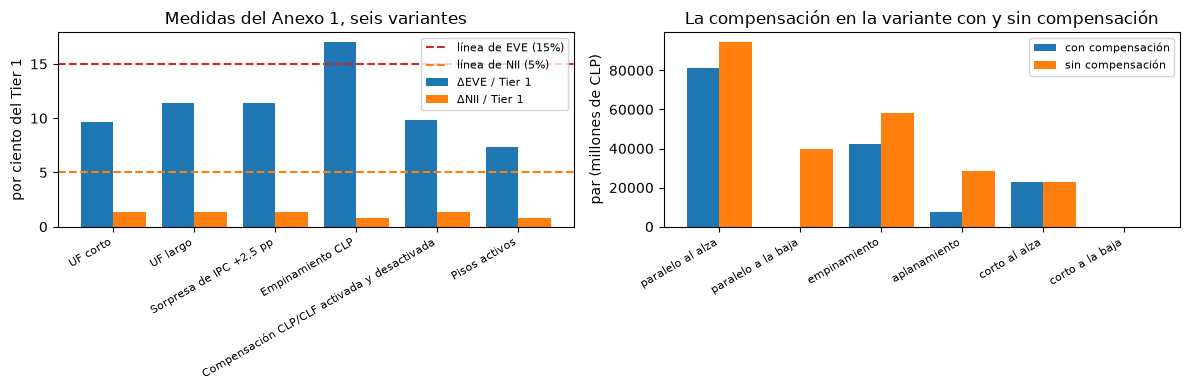

In [14]:
# Dibujar las dos razones de las seis variantes contra sus líneas y el par con y sin compensación
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(ids))
left.bar(x - 0.2, [summary[v][0] * 100 for v in ids], 0.4, label="ΔEVE / Tier 1")
left.bar(x + 0.2, [summary[v][1] * 100 for v in ids], 0.4, label="ΔNII / Tier 1")
left.axhline(15, color="tab:red", linestyle="--", label="línea de EVE (15%)")
left.axhline(5, color="tab:orange", linestyle="--", label="línea de NII (5%)")
left.set_xticks(x)
left.set_xticklabels([variants[v]["outputs"]["variant"]["label"][LANG] for v in ids], rotation=30, ha="right", fontsize=8)
left.set_ylabel("por ciento del Tier 1")
left.set_title("Medidas del Anexo 1, seis variantes")
left.legend(fontsize=8)
pairs = variants["offset-on-off"]["outputs"]["eve"]["rows"]
right.bar(np.arange(6) - 0.2, [r["pair"]["with_offset"] for r in pairs], 0.4, label="con compensación")
right.bar(np.arange(6) + 0.2, [r["pair"]["without_offset"] for r in pairs], 0.4, label="sin compensación")
right.set_xticks(np.arange(6))
right.set_xticklabels([NAME[r["shock"]] for r in pairs], rotation=30, ha="right", fontsize=8)
right.set_ylabel("par (millones de CLP)")
right.set_title("La compensación en la variante con y sin compensación")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

- **Los dos tramos.** El tramo en pesos tiene activos de 4.988.540 y pasivos de 3.917.062 (millones de CLP), una posición neta activa de 1.071.478. El tramo UR es pequeño en su propia unidad, 65,89 y 71,94 millones de CLF, pero a 40.877,73 pesos por UF su posición neta de -6,05 millones de CLF son -247.264 millones de CLP, que es el -30 por ciento del Tier 1 para el que se construyó la variante. Esa posición, el 30 por ciento del Tier 1 y no el tamaño del libro en UF, fija el cargo.
- **Las curvas.** El motor reconstruye exactamente los dos ajustes Nelson-Siegel: la curva en pesos con un decaimiento de 1 año y un error de 0,50 pb, la curva UF con un decaimiento de 2,5 años y 0,41 pb. En la banda más corta la curva en pesos está en 4,50 por ciento y la UF en 1,21 por ciento, a 25 años en 5,91 y 2,84 por ciento: la curva nominal queda unos 3 puntos sobre la real, como lo implicaría la compensación por inflación que cobra el mercado. La curva en pesos descansa en tres rendimientos de mercado y la tasa de política, así que su punto más corto es una tasa de política y no de mercado; un validador debe leerlo como una elección abierta, no como una medición.
- **Topes y multiplicadores.** El segmento minorista operacional pide 95 por ciento y 5,5 años y se corta a 90 por ciento y 5 años, el mayorista pide 60 por ciento y 4,5 años y se corta a 50 por ciento y 4 años, y el minorista no operacional pide exactamente sus topes y no se corta. Los multiplicadores son los de Basilea, repetidos por el Anexo: con un prepago base de 5 por ciento, los choques paralelo al alza, empinamiento y corto al alza dan 4 por ciento y los otros tres 6 por ciento, y con un rescate anticipado base de 5 por ciento los choques paralelo al alza, aplanamiento y corto al alza dan 6 por ciento y los otros tres 4 por ciento.
- **El delta EVE.** En la variante de UF corto ambos tramos pierden bajo el choque paralelo al alza (34.216 el peso y 45.427 la UR), que es el peor choque, así que el par es su suma, 79.643, y la compensación no hace nada. Donde los tramos van en direcciones opuestas la compensación actúa: en el empinamiento el par es 34.337 con ella y 38.748 sin ella, en el aplanamiento 0 con ella y 16.211 sin ella. La medida del Anexo es el máximo entre los seis choques, así que la compensación cambia la medida solo si cambia el peor choque, como muestra en la última figura la variante con y sin compensación. El delta EVE es 9,66 por ciento del Tier 1.
- **El delta NII y el cargo.** El peso gana cuando suben las tasas (-7.059) y la UR pierde (8.415): el par con compensación es 4.885, frente a 8.415 sin ella. El cargo es 6.182, el 55,9 por ciento del delta NII de 11.067: más de la mitad de la medida de NII es función del tamaño de la posición neta en UF, no del choque. El cargo es el mismo, 6.182, para una posición corta neta de -247.264 y una larga neta de +247.264, mientras que una sorpresa de inflación de 2,5 puntos es una pérdida de 6.182 para el banco corto y una ganancia de 6.182 (el efecto versionado es -6.182) para el largo: el cargo estándar es un recargo de un solo lado, el escenario es de dos lados.
- **Las pruebas.** El banco de UF corto está en 1,34 por ciento del Tier 1 para el delta NII (línea 5), en 9,66 por ciento para el delta EVE (línea 15) y en 4,03 por ciento del margen a 12 meses (línea 18): no priorizado. De las seis variantes solo el empinamiento en pesos cruza una línea, el delta EVE en 17,06 por ciento, y es priorizado; la variante de UF largo, en 11,38 por ciento, es la más cercana de las otras.
- **Los pisos.** Ningún piso actúa en ninguna de las seis variantes. La tasa posterior al choque más cercana es la tasa UR de la primera banda bajo una caída de 300 pb, en -1,795 por ciento frente a un piso de -2 por ciento, a 20,48 pb; las siguientes están a 50,21 pb (el peso, corto a la baja), 70,65 y 120,48 pb. La variante `floors-active`, con 70 por ciento de los préstamos comerciales en UF a tasa flotante, se construyó para poner en juego los pisos y no lo logra: su nombre declara la intención, no el resultado. Con las tasas de hoy el piso es una regla que el motor implementa y prueba (cuaderno 02), no una que mueva un número.
- **Lo que el cuaderno no muestra.** El NII dinámico y las distribuciones de Hull-White de los dos tramos, el precio de la propia indexación a la UF (la tasa real está en la curva, la inflación está en el cargo), y cualquier verificación de las cifras chilenas contra una segunda implementación: no hay con qué compararlas (cuaderno 08).

## Resumen

- El Anexo chileno trata la UF como una sola moneda, la UR, con su propia curva, sus propios tamaños de choque, un piso en -2 por ciento y un cargo por reajustabilidad de 2,5 por ciento de la posición neta en UF en valor absoluto; el motor reproduce cada pieza y nunca convierte entre monedas.
- El delta EVE toma los seis choques en cada tramo, empareja los tramos con la compensación de 50 por ciento sobre el tramo con ganancia y toma el peor choque; el delta NII usa un único choque de 300 pb, el mismo emparejamiento y suma el cargo una sola vez.
- El cargo no depende del choque ni del signo de la posición, así que un banco largo neto en UF, que gana con la inflación, paga lo mismo que uno corto neto.
- Tres pruebas hacen priorizado a un banco: el delta NII sobre 5 por ciento del Tier 1, el delta EVE sobre 15 por ciento, y el delta NII sobre 18 por ciento del margen a 12 meses; una de las seis variantes cruza una línea.
- Ningún piso actúa en ninguna de las seis variantes; la tasa posterior al choque más cercana está a 20,48 pb de su piso, en el tramo UR bajo una caída de 300 pb.

**Qué probar a continuación.** Elige la variante `long-uf` como principal en la primera celda y lee cómo cambia el par del primer choque. Después sigue con el cuaderno 07, el estado del arte.

## Referencias

- CMF, Recopilación Actualizada de Normas, capítulo 21-13, Anexo 1, Determinación de la exposición al riesgo de mercado en el libro de banca (Circulares 2.270 de 2020 y 2.365 de 2025). https://www.cmfchile.cl/portal/principal/623/articles-29808_doc_pdf.pdf
- BCBS, Standards: Interest rate risk in the banking book, SRP31 (los choques, las bandas, los topes y los multiplicadores, repetidos por el Anexo). https://www.bis.org/basel_framework/chapter/SRP/31.htm
- CMF, Informe del Desempeño del Sistema Bancario y Cooperativas, agosto de 2026, Cuadro N 1 (los agregados del banco sintético). https://www.cmfchile.cl/portal/estadisticas/617/articles-113863_recurso_1.pdf
- Banco Central de Chile, Base de Datos Estadísticos, cuadro F022 (rendimientos de mercado secundario) y serie F073.UFF.PRE.Z.D (la UF), términos de uso. https://si3.bcentral.cl/estadisticas/Principal1/Web_Services/terminos_condiciones.html
- Nelson, C. R. y Siegel, A. F. (1987), Parsimonious modeling of yield curves, Journal of Business 60(4). https://doi.org/10.1086/296409
- Dossier 03 de la investigación de Contraste (Chile), sección F.2.